## Importing libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
import random

### Load the dataset

In [2]:
train_df = pd.read_csv("Dataset/train.csv")
test_df = pd.read_csv("Dataset/test.csv")
print("Train CSV shape:", train_df.shape)
print("Test CSV shape:", test_df.shape)

Train CSV shape: (42000, 785)
Test CSV shape: (28000, 784)


### Create a pytorch dataset

In [3]:
class MNISTDataset(Dataset):
    def __init__(self, dataframe, transform=None, is_test=False):
        # Separate labels and images
        if is_test:
            self.images = dataframe.values.reshape(-1, 28, 28).astype(np.float32) / 255.0
            self.labels = None
        else:
            self.labels = dataframe.iloc[:, 0].values
            self.images = dataframe.iloc[:, 1:].values.reshape(-1, 28, 28).astype(np.float32) / 255.0
        
        self.transform = transform
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx] if self.labels is not None else -1
        
        # Add channel dimension: (28, 28) -> (1, 28, 28)
        image = torch.tensor(image).unsqueeze(0)
        
        if self.transform:
            image = self.transform(image)
        
        if self.labels is not None:
            return image, torch.tensor(label, dtype=torch.long)
        return image

### Define transform pipeline

In [4]:
train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
]
                                     )
test_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
]
                                    )

In [5]:
train_data = MNISTDataset(train_df, transform = train_transforms, is_test= False)

test_data = MNISTDataset(test_df, transform = test_transforms, is_test = True)

train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_data, val_data = random_split(train_data, [train_size, val_size])
# Put them into the Dataloader
batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

### Define a deep CNN model

In [6]:
class DeepCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.conv = nn.Sequential(
        nn.Conv2d(1, 32, kernel_size= 3, padding= 1),
        nn.ReLU(inplace= True),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size= 3, padding = 1),
        nn.ReLU(inplace = True),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2)
        )

        self.fc = nn.Sequential(
        nn.Flatten(),
        nn.Linear(128 * 3 * 3, 256),
        nn.ReLU(),
        nn.Dropout(0.25),
        nn.Linear(256, 10)
        )
    def forward(self, x):
            return self.fc(self.conv(x))

device = "cuda" if torch.cuda.is_available() else "cpu"
model_0 = DeepCNN().to(device)

In [7]:
# Loss Function
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_0.parameters(), lr=0.001)

# Optional learning rate scheduler: step down by factor 0.1 every 10 epochs
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

In [8]:
torch.manual_seed(67)
EPOCHS = 15

# Training loop
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    # --- Training ---
    model_0.train()
    running_loss, correct, total = 0, 0, 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model_0(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    
    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)
    
    # --- Validation ---
    model_0.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_0(images)
            loss = loss_fn(outputs, labels)
            
            val_loss += loss.item()
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)
    
    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc)
    
    # Step the scheduler
    scheduler.step()
    
    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

Epoch 1/15 | Train Loss: 0.2634, Train Acc: 0.9155 | Val Loss: 0.0711, Val Acc: 0.9773
Epoch 2/15 | Train Loss: 0.0774, Train Acc: 0.9756 | Val Loss: 0.0695, Val Acc: 0.9776
Epoch 3/15 | Train Loss: 0.0567, Train Acc: 0.9826 | Val Loss: 0.0517, Val Acc: 0.9835
Epoch 4/15 | Train Loss: 0.0476, Train Acc: 0.9853 | Val Loss: 0.0548, Val Acc: 0.9838
Epoch 5/15 | Train Loss: 0.0409, Train Acc: 0.9871 | Val Loss: 0.0455, Val Acc: 0.9863
Epoch 6/15 | Train Loss: 0.0352, Train Acc: 0.9889 | Val Loss: 0.0528, Val Acc: 0.9844
Epoch 7/15 | Train Loss: 0.0369, Train Acc: 0.9882 | Val Loss: 0.0481, Val Acc: 0.9863
Epoch 8/15 | Train Loss: 0.0290, Train Acc: 0.9907 | Val Loss: 0.0460, Val Acc: 0.9871
Epoch 9/15 | Train Loss: 0.0270, Train Acc: 0.9914 | Val Loss: 0.0394, Val Acc: 0.9876
Epoch 10/15 | Train Loss: 0.0241, Train Acc: 0.9921 | Val Loss: 0.0456, Val Acc: 0.9871
Epoch 11/15 | Train Loss: 0.0170, Train Acc: 0.9945 | Val Loss: 0.0345, Val Acc: 0.9900
Epoch 12/15 | Train Loss: 0.0126, Train A

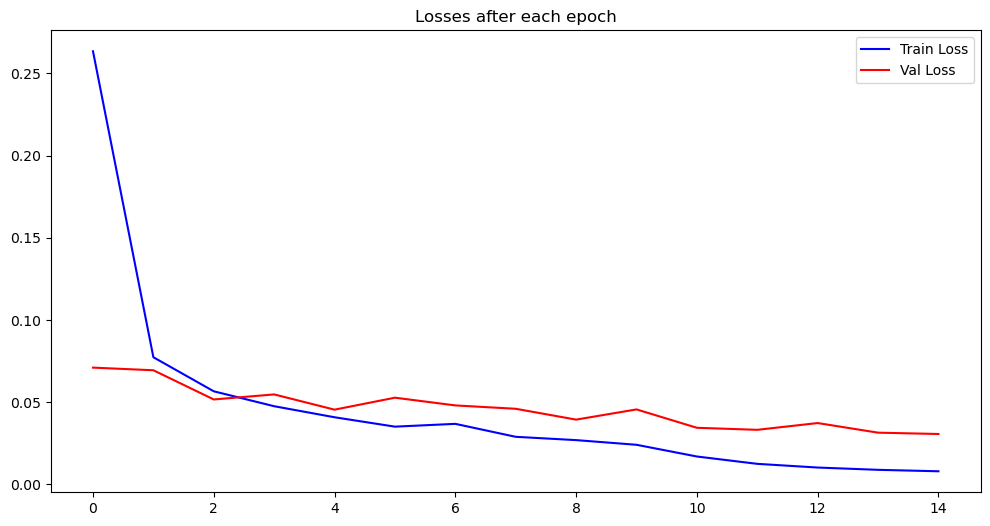

In [9]:
plt.figure(figsize = (12,6))
plt.plot(train_losses, c = "b", label = "Train Loss")
plt.plot(val_losses, c = "r", label = "Val Loss")
plt.title("Losses after each epoch")
plt.legend()
plt.show()

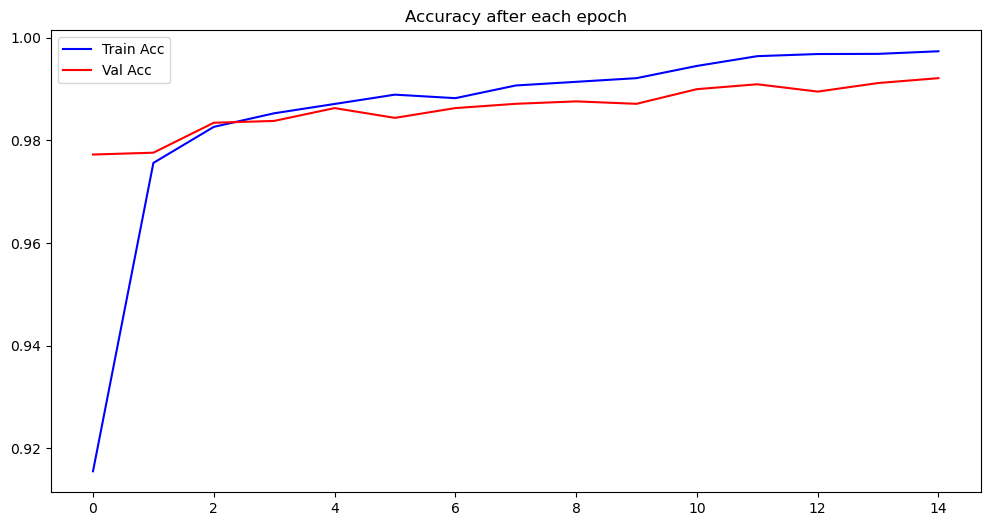

In [10]:
plt.figure(figsize = (12, 6))
plt.plot(train_accs, c = "b", label = "Train Acc")
plt.plot(val_accs, c = "r", label = "Val Acc")
plt.title("Accuracy after each epoch")
plt.legend()
plt.show()

In [12]:
torch.save(model_0.state_dict(), 'outputs/best_model.pth')